In [47]:
import pandas as pd
import pingouin as pg

# Load data
df = pd.read_csv("https://raw.githubusercontent.com/fivethirtyeight/data/master/hate-crimes/hate_crimes.csv")

pg.corr(df["avg_hatecrimes_per_100k_fbi"],df["gini_index"])


,n,r,CI95,p_val,BF10,power
pearson,50,0.421272,"[0.16, 0.63]",0.002314,16.02,0.874232


In [51]:
import pandas as pd
import pingouin as pg

# Load data
df = pd.read_csv("https://raw.githubusercontent.com/fivethirtyeight/data/master/hate-crimes/hate_crimes.csv")

observed_r = pg.corr(df["avg_hatecrimes_per_100k_fbi"],df["gini_index"])
print(f"Observed correlation: {observed_r}")
r=observed_r["r"].iloc[0] 
pg.bayesfactor_pearson(r=r, n=len(df)) #BF from r and n=sample size

Observed correlation:           n         r          CI95     p_val   BF10     power
pearson  50  0.421272  [0.16, 0.63]  0.002314  16.02  0.874232


17.486723911151408

In [46]:
import pandas as pd #, numpy as np
df = pd.DataFrame({
    "x": [3, 5, 8, 10, 12]})
sd_x = df['x'].std() #**2 -> Variance
#sd_x = np.sqrt(((df['x']-df['x'].mean())**2).sum()/(len(df)-1))

print(f"Standard deviation of x: {sd_x}")


Standard deviation of x: 3.646916505762094


In [21]:
import numpy as np, pandas as pd

np.random.seed(123)
df = pd.DataFrame({"x": [3, 5, 8, 10, 12]})

df["y"] = df["x"] + np.round(np.random.normal(0, 2, len(df)))
df["y_dev"] = df["y"] - df["y"].mean()
df["x_dev"] = df["x"] - df["x"].mean()
df["crossproduct"] = df["x_dev"] * df["y_dev"]

result = pd.DataFrame({
    "covXY": [df["crossproduct"].sum() / (len(df) - 1)],
    "corXY": [df["crossproduct"].sum() / ((len(df) - 1) * df["x"].std() * df["y"].std())]
})

result

,covXY,corXY
0,11.5,0.842768


In [19]:
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
hate = pd.read_csv("https://raw.githubusercontent.com/fivethirtyeight/data/master/hate-crimes/hate_crimes.csv")

#observed_r = pg.corr(hate["avg_hatecrimes_per_100k_fbi"],hate["gini_index"])["r"][0]
observed_r = hate["avg_hatecrimes_per_100k_fbi"].corr(hate["gini_index"])

shuffle_r = []

for _ in range(5000):

    x_shuffled = np.random.permutation(hate["avg_hatecrimes_per_100k_fbi"])
    #
    r = pd.Series(x_shuffled).corr(hate["gini_index"])
    #adding the correlation coefficient to the list of shuffled correlations
    shuffle_r.append(r)
result =f"Correlation r: {observed_r:.3f} Permutation p = {np.mean(np.array(shuffle_r) >= observed_r):.4f}"
print(result)

Observed correlation: 0.421 Permutation p = 0.0072


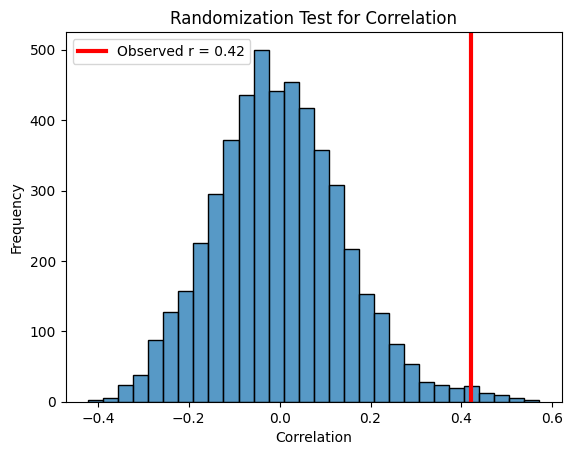

In [57]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

hate = pd.read_csv("https://raw.githubusercontent.com/fivethirtyeight/data/refs/heads/master/hate-crimes/hate_crimes.csv")
observed_r = hate["avg_hatecrimes_per_100k_fbi"].corr(hate["gini_index"])

shuffle_r = []

for i in range(5000):
    x_shuffled = np.random.permutation(
        hate["avg_hatecrimes_per_100k_fbi"]
    )
    r = pd.Series(x_shuffled).corr(hate["gini_index"])
    shuffle_r.append(r)

sns.histplot(shuffle_r, bins=30)

plt.axvline(
    observed_r,
    color="red",
    linewidth=3,
    label=f"Observed r = {observed_r:.2f}"
)

plt.legend()
plt.xlabel("Correlation")
plt.ylabel("Frequency")
plt.title("Randomization Test for Correlation")
plt.show()
